In [131]:
import json
from pathlib import Path

import pandas as pd
from utils import _get_vocabulary, _get_word_counts, _tokenize

ImportError: cannot import name '_get_word_counts' from 'utils' (/home/prenassipaolo/Projects/banking_query_triage/notebooks/utils.py)

In [ ]:
TRAIN_FILE = Path("../data/raw/train.csv")
TEST_FILE = Path("../data/raw/test.csv")
CATEGORIES_FILE = Path("../data/raw/categories.json")

In [ ]:
df_raw_train = pd.read_csv(TRAIN_FILE)
df_raw_test = pd.read_csv(TEST_FILE)
with open(CATEGORIES_FILE, "r") as f:
    df_raw_categories = json.load(f)

# EDA

In [ ]:
df_raw_train.describe()

,text,category
count,10003,10003
unique,10003,77
top,I am still waiting on my card?,card_payment_fee_charged
freq,1,187


In [ ]:
df_raw_test.describe()

,text,category
count,3080,3080
unique,3080,77
top,How do I locate my card?,card_arrival
freq,1,40


In [ ]:
df_raw_train.category.value_counts()

category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
                                                   ... 
lost_or_stolen_card                                  82
card_swallowed                                       61
card_acceptance                                      59
virtual_card_not_working                             41
contactless_not_working                              35
Name: count, Length: 77, dtype: int64

In [ ]:
df_raw_test.category.value_counts()

category
card_arrival                        40
card_linking                        40
exchange_rate                       40
card_payment_wrong_exchange_rate    40
extra_charge_on_statement           40
                                    ..
cash_withdrawal_charge              40
card_about_to_expire                40
apple_pay_or_google_pay             40
verify_my_identity                  40
country_support                     40
Name: count, Length: 77, dtype: int64

In [ ]:
print(len(df_raw_categories))
print(len(set(df_raw_categories)))

77
77


In [ ]:
print([c for c in df_raw_train.category.unique() if c not in df_raw_categories])
print([c for c in df_raw_test.category.unique() if c not in df_raw_categories])
print(
    [
        c
        for c in df_raw_categories
        if c not in df_raw_train.category.unique()
        and c not in df_raw_test.category.unique()
    ]
)

[]
[]
[]


<Axes: title={'center': 'Train Category Distribution'}, xlabel='Category', ylabel='Count'>

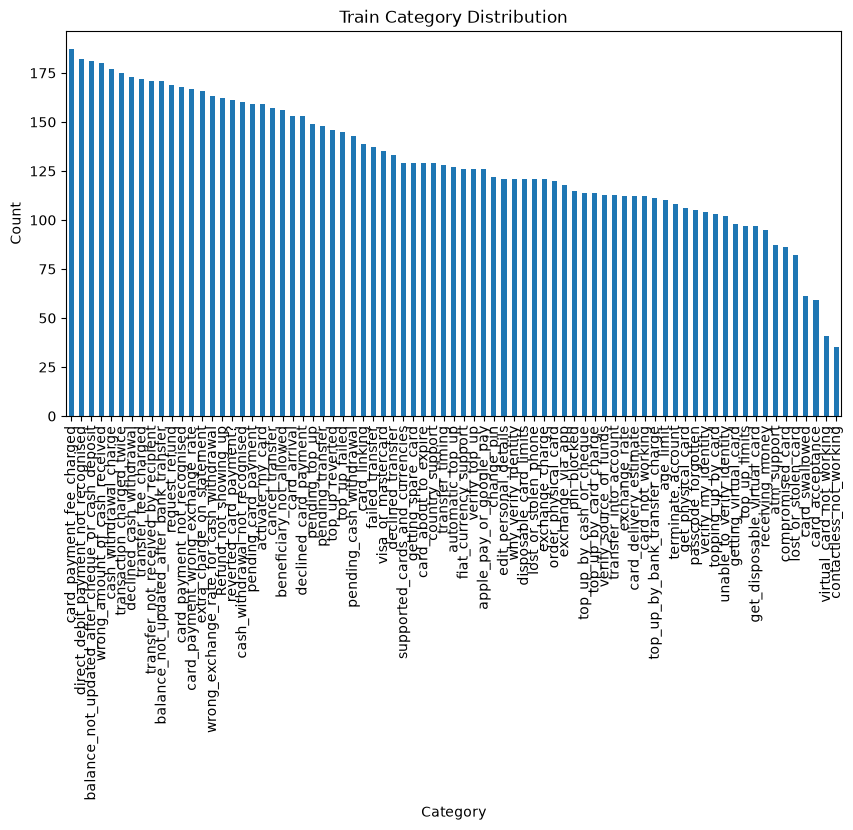

In [ ]:
df_raw_train.category.value_counts().plot(
    kind="bar",
    title="Train Category Distribution",
    xlabel="Category",
    ylabel="Count",
    figsize=(10, 5),
)

In [ ]:
df_raw_train.iloc[0]

text        I am still waiting on my card?
category                      card_arrival
Name: 0, dtype: str

<Axes: title={'center': 'Train Text Word Count Distribution'}, xlabel='Word Count', ylabel='Count'>

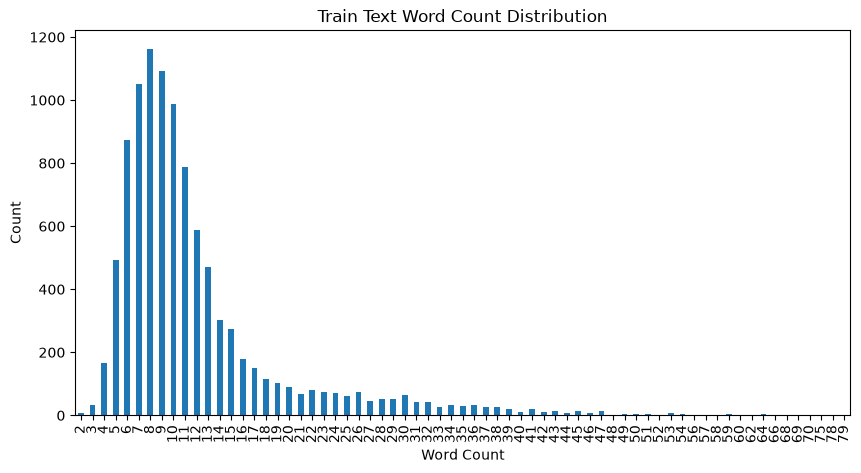

In [ ]:
df_raw_train.text.apply(lambda x: len(x.split())).value_counts().sort_index().plot(
    kind="bar",
    title="Train Text Word Count Distribution",
    xlabel="Word Count",
    ylabel="Count",
    figsize=(10, 5),
)

In [ ]:
# Tokenize the text
# - Replace punctuation with spaces
# - Split the text into words
# - Keep only alphanumeric characters
# - Convert to lowercase
# - Remove stopwords


df_raw_train["text_tokenized"] = df_raw_train.text.apply(_tokenize)

In [ ]:
# Get all the words in the training set


vocabulary = _get_vocabulary(df_raw_train["text_tokenized"])

In [ ]:
len(vocabulary)

2324

In [ ]:
# Get value counts for each word in the training set


word_counts = _get_word_counts(df_raw_train["text_tokenized"], vocabulary)

In [ ]:
{
    k: v
    for k, v in sorted(word_counts.items(), key=lambda item: item[1], reverse=True)[:20]
}

{'i': 8807,
 'my': 5684,
 'card': 2682,
 'is': 2377,
 'can': 2070,
 'it': 2062,
 'do': 1849,
 't': 1582,
 'what': 1542,
 'how': 1524,
 'why': 1368,
 'up': 1360,
 'account': 1352,
 'you': 1226,
 'money': 1133,
 'was': 1090,
 'transfer': 1084,
 'top': 1045,
 'me': 1038,
 'that': 1018}

In [ ]:
df_raw_train.iloc[0]

text                 I am still waiting on my card?
category                               card_arrival
text_tokenized    [i, am, still, waiting, my, card]
Name: 0, dtype: object

In [ ]:
df_raw_train.shape

(10003, 3)

In [ ]:
# Remove duplicates
df_raw_train_unique = df_raw_train.copy()
df_raw_train_unique["text_normalized"] = df_raw_train_unique.text_tokenized.apply(
    lambda x: " ".join(x)
)
df_raw_train_unique = df_raw_train_unique.drop_duplicates(
    subset=["category", "text_normalized"]
)

In [ ]:
df_raw_train_unique.describe()

,text,category,text_tokenized,text_normalized
count,9925,9925,9925,9925
unique,9925,77,9924,9924
top,I am still waiting on my card?,card_payment_fee_charged,"[has, my, top, up, gone, through]",has my top up gone through
freq,1,187,2,2
